# Modularity on the Karate Club Graph
**DSC212: Graph Theory Module, Research Assignment**

**Reference:** Newman, M. E. J. (2006). *Modularity and community structure in networks.* PNAS 103(23): 8577-8582.

In [ ]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

# Load the graph. weight=None makes A contain only 0 and 1.
G = nx.karate_club_graph()
n = G.number_of_nodes()
m = G.number_of_edges()
print("people (n):", n)
print("friendships (m):", m)

A = nx.to_numpy_array(G, nodelist=range(n), weight=None)   # adjacency matrix
k = A.sum(axis=1)                                          # degrees
B = A - np.outer(k, k) / (2 * m)                           # modularity matrix

# Quick checks from the handout
print("B is symmetric:", np.allclose(B, B.T))
print("B times all-ones vector is 0:", np.allclose(B @ np.ones(n), 0))

people (n): 34
friendships (m): 78
B is symmetric: True
B times all-ones vector is 0: True

## 1. Splitting one group into two

In [ ]:
def try_split(group, newman=False):
    group = sorted(group)
    Bc = B[np.ix_(group, group)]                 # block of B for this group
    if newman:                                   # only for section 9
        Bc = Bc - np.diag(Bc.sum(axis=1))

    values, vectors = np.linalg.eigh(Bc)         # eigenvalues come out smallest to biggest
    biggest = values[-1]
    u = vectors[:, -1]                           # leading eigenvector

    if biggest <= 1e-8:                          # not above 0 -> stop
        return None, biggest

    s = np.where(u > 0, 1, -1)                   # +1 / -1 labels from the sign
    if abs(s.sum()) == len(s):                   # everybody on the same side -> nothing to split
        return None, biggest

    if newman:                                   # only for section 9: make sure Q really goes up
        if s @ Bc @ s / (4 * m) <= 1e-8:
            return None, biggest

    part1 = [group[i] for i in range(len(group)) if s[i] == 1]
    part2 = [group[i] for i in range(len(group)) if s[i] == -1]
    return (part1, part2), biggest

## 2. Splitting again and again

In [ ]:
def split_all(newman=False, show=True):
    todo = [list(range(n))]          # groups still to check
    finished = []                    # groups that cannot be split any more
    history = [[list(range(n))]]     # history[i] = all communities after split i
    split_number = 0
    while todo:
        group = todo.pop(0)
        result, biggest = try_split(group, newman)
        if result is None:
            finished.append(sorted(group))
            if show:
                print("group of", len(group), "people: biggest eigenvalue =", round(biggest, 3), "-> stop")
        else:
            split_number += 1
            todo.append(result[0])
            todo.append(result[1])
            if show:
                print("split", split_number, ": group of", len(group), "->",
                      len(result[0]), "and", len(result[1]),
                      "| biggest eigenvalue =", round(biggest, 3))
            history.append([sorted(c) for c in todo + finished])
    return history

history = split_all()
communities = history[-1]
print()
print("Number of splits:", len(history) - 1)
print("Number of communities:", len(communities))
for i, c in enumerate(communities):
    print("community", i + 1, ":", c)

split 1 : group of 34 -> 16 and 18 | biggest eigenvalue = 4.977
split 2 : group of 16 -> 10 and 6 | biggest eigenvalue = 2.944
split 3 : group of 18 -> 5 and 13 | biggest eigenvalue = 2.504
group of 10 people: biggest eigenvalue = 2.571 -> stop
split 4 : group of 6 -> 1 and 5 | biggest eigenvalue = 2.148
group of 5 people: biggest eigenvalue = 1.876 -> stop
group of 13 people: biggest eigenvalue = 2.356 -> stop
group of 1 people: biggest eigenvalue = -0.006 -> stop
group of 5 people: biggest eigenvalue = 2.147 -> stop

Number of splits: 4
Number of communities: 5
community 1 : [24, 25, 27, 28, 31]
community 2 : [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
community 3 : [11]
community 4 : [4, 5, 6, 10, 16]
community 5 : [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]

## 3. Checking the result

Q = s^T B s / (4m)

In [ ]:
def modularity_of(communities):
    # Q = (1/2m) * sum over pairs in the same community of B[i][j]
    total = 0
    for c in communities:
        total += B[np.ix_(c, c)].sum()
    return total / (2 * m)

print("Q after each split (my formula vs NetworkX):")
for i, comms in enumerate(history):
    mine = modularity_of(comms)
    theirs = nx.community.modularity(G, [set(c) for c in comms], weight=None)
    print("  iteration", i, ":", round(mine, 4), "|", round(theirs, 4))

Q after each split (my formula vs NetworkX):
  iteration 0 : -0.0 | 0.0
  iteration 1 : 0.3715 | 0.3715
  iteration 2 : 0.3898 | 0.3898
  iteration 3 : 0.4081 | 0.4081
  iteration 4 : 0.4094 | 0.4094

## 4. Drawing the graph after each split

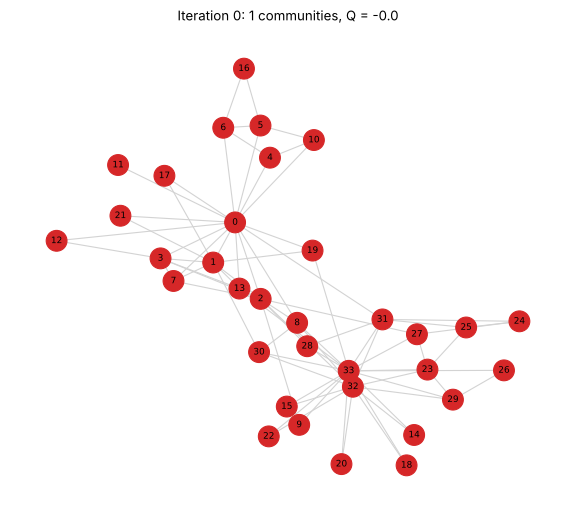

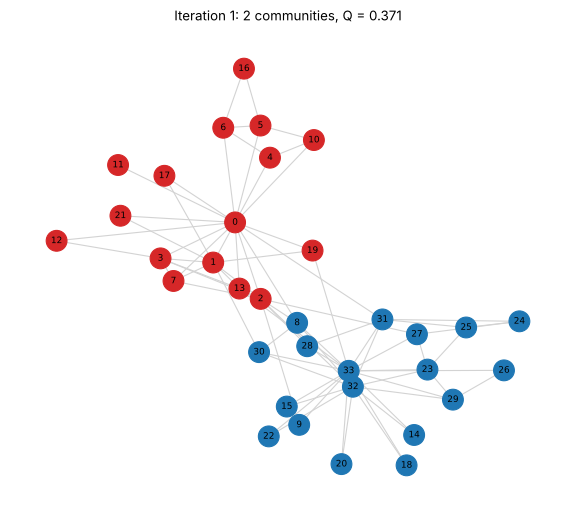

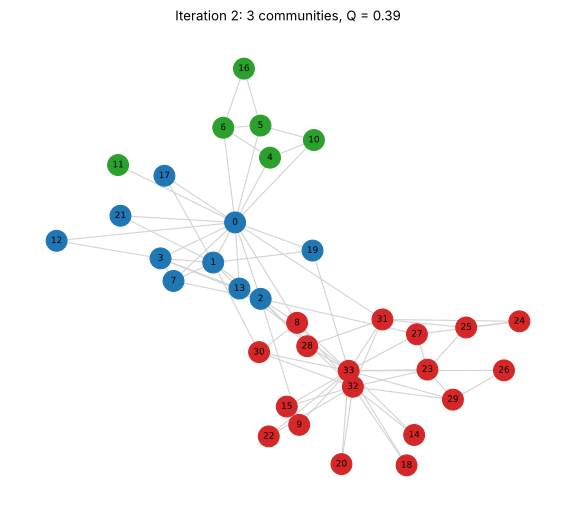

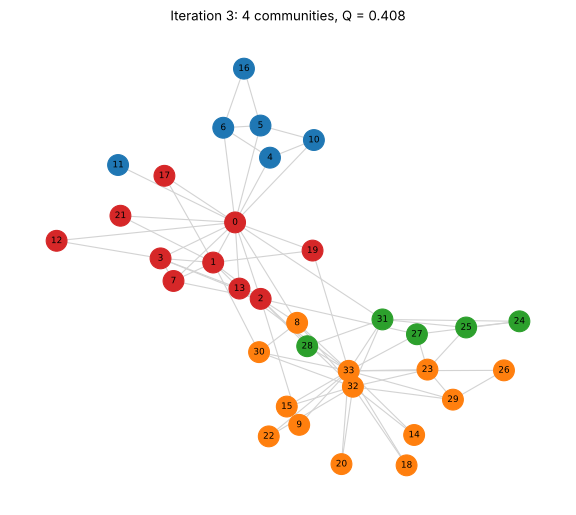

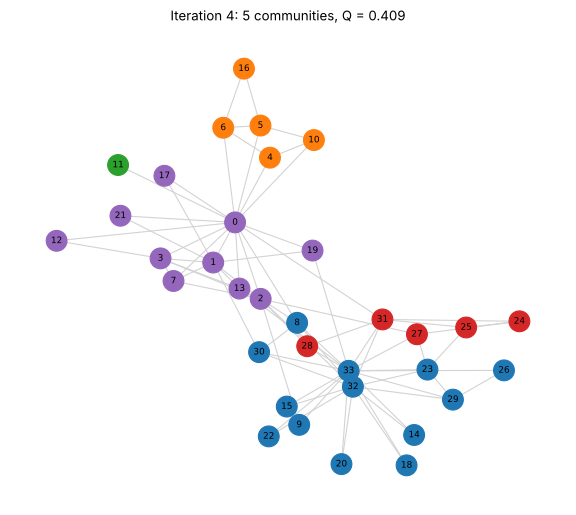

In [ ]:
pos = nx.spring_layout(G, seed=42)      # fixed layout, used for every picture
palette = ["tab:red", "tab:blue", "tab:green", "tab:orange", "tab:purple",
           "tab:brown", "tab:pink", "tab:cyan"]

for it, comms in enumerate(history):
    color_of = {}
    for ci, c in enumerate(comms):
        for node in c:
            color_of[node] = palette[ci % len(palette)]
    colors = [color_of[v] for v in range(n)]

    plt.figure(figsize=(7, 6))
    nx.draw(G, pos, node_color=colors, with_labels=True, node_size=350,
            font_size=8, edge_color="lightgray")
    plt.title("Iteration " + str(it) + ": " + str(len(comms)) + " communities, Q = "
              + str(round(modularity_of(comms), 3)))
    plt.show()

## 5. Does the first split match the real split?

In [ ]:
first_split = history[1]
real = [G.nodes[v]["club"] for v in range(n)]

# Pick which of my two groups matches "Mr. Hi" better
group_a, group_b = first_split
hi_in_a = sum(1 for v in group_a if real[v] == "Mr. Hi")
hi_in_b = sum(1 for v in group_b if real[v] == "Mr. Hi")
if hi_in_a >= hi_in_b:
    hi_group, officer_group = group_a, group_b
else:
    hi_group, officer_group = group_b, group_a

wrong = [v for v in hi_group if real[v] != "Mr. Hi"] + \
        [v for v in officer_group if real[v] != "Officer"]

print("Group matching Mr. Hi    :", hi_group)
print("Group matching the Officer:", officer_group)
print("People placed in the wrong group:", sorted(wrong))
print("Correct:", n - len(wrong), "out of", n)

Group matching Mr. Hi    : [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
Group matching the Officer: [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
People placed in the wrong group: [8]
Correct: 33 out of 34

## 6. Node metrics after each split

In [ ]:
metrics = {}    # metrics[iteration][metric name][node] = value

for it, comms in enumerate(history):
    deg, bet, clo, clu = {}, {}, {}, {}
    for c in comms:
        sub = G.subgraph(c)
        deg.update(nx.degree_centrality(sub))
        bet.update(nx.betweenness_centrality(sub))
        clo.update(nx.closeness_centrality(sub))
        clu.update(nx.clustering(sub))
    metrics[it] = {"Degree centrality": deg, "Betweenness centrality": bet,
                   "Closeness centrality": clo, "Clustering coefficient": clu}

# Show the top 3 nodes for each metric at each iteration
for name in ["Degree centrality", "Betweenness centrality", "Closeness centrality", "Clustering coefficient"]:
    print(name)
    for it in metrics:
        values = metrics[it][name]
        top = sorted(values, key=values.get, reverse=True)[:3]
        print("  iteration", it, ": top 3 nodes =", top,
              [round(values[v], 2) for v in top])
    print()

Degree centrality
  iteration 0 : top 3 nodes = [33, 0, 32] [0.52, 0.48, 0.36]
  iteration 1 : top 3 nodes = [0, 33, 32] [0.93, 0.88, 0.65]
  iteration 2 : top 3 nodes = [0, 1, 33] [1.0, 0.89, 0.88]
  iteration 3 : top 3 nodes = [0, 33, 1] [1.0, 1.0, 0.89]
  iteration 4 : top 3 nodes = [33, 11, 0] [1.0, 1, 1.0]

Betweenness centrality
  iteration 0 : top 3 nodes = [0, 33, 32] [0.44, 0.3, 0.15]
  iteration 1 : top 3 nodes = [0, 33, 32] [0.69, 0.57, 0.2]
  iteration 2 : top 3 nodes = [33, 0, 1] [0.57, 0.35, 0.22]
  iteration 3 : top 3 nodes = [33, 24, 31] [0.55, 0.5, 0.5]
  iteration 4 : top 3 nodes = [33, 24, 31] [0.55, 0.5, 0.5]

Closeness centrality
  iteration 0 : top 3 nodes = [0, 2, 33] [0.57, 0.56, 0.55]
  iteration 1 : top 3 nodes = [0, 33, 32] [0.94, 0.89, 0.74]
  iteration 2 : top 3 nodes = [0, 1, 33] [1.0, 0.9, 0.89]
  iteration 3 : top 3 nodes = [0, 33, 1] [1.0, 1.0, 0.9]
  iteration 4 : top 3 nodes = [33, 0, 1] [1.0, 1.0, 0.9]

Clustering coefficient
  iteration 0 : top 3 no

## 7. How the metrics change across iterations

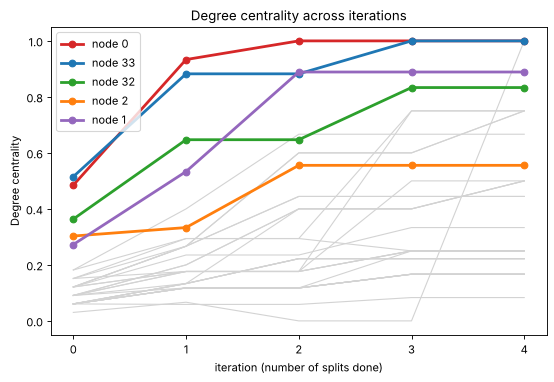

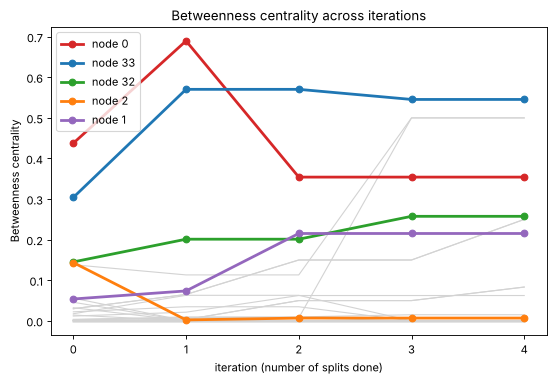

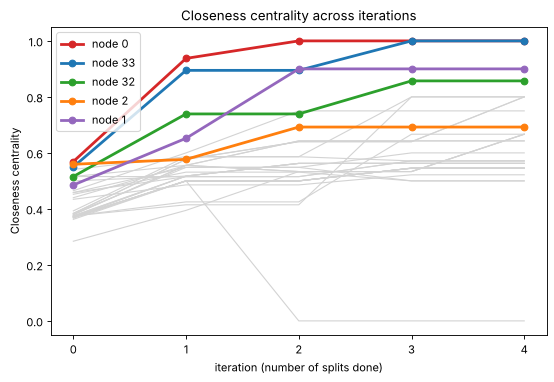

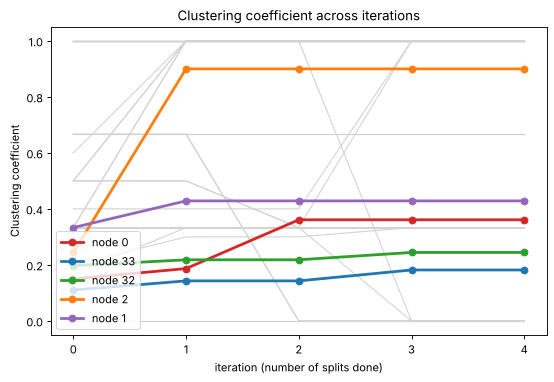

In [ ]:
iterations = list(metrics.keys())
highlight = {0: "tab:red", 33: "tab:blue", 32: "tab:green", 2: "tab:orange", 1: "tab:purple"}

for name in ["Degree centrality", "Betweenness centrality", "Closeness centrality", "Clustering coefficient"]:
    plt.figure(figsize=(8, 5))
    for v in range(n):
        if v not in highlight:
            plt.plot(iterations, [metrics[it][name][v] for it in iterations],
                     color="lightgray", linewidth=1)
    for v, col in highlight.items():
        plt.plot(iterations, [metrics[it][name][v] for it in iterations],
                 color=col, linewidth=2.5, marker="o", label="node " + str(v))
    plt.title(name + " across iterations")
    plt.xlabel("iteration (number of splits done)")
    plt.ylabel(name)
    plt.xticks(iterations)
    plt.legend()
    plt.show()

## 9. Discussion

The first split divides the club into two groups, and 33 of the 34 people land on the same side as in the real split. Only node 8 is wrong. Node 8 has 5 friends: 2 are on Mr. Hi's side (nodes 0 and 2) and 3 are on the officer's side (nodes 30, 32 and 33), so the graph alone points to the officer's side, but he really joined Mr. Hi. Further splits then break the two factions into smaller groups. The final modularity is about 0.41.

**Which nodes stay central?**
- **Node 0 (Mr. Hi) and node 33 (the officer's side)** stay central the whole time. At every iteration both are in the top 3 for degree centrality and for closeness centrality. (At iteration 4, node 11 appears in the top 3 for degree only because it is a community of one person, and NetworkX gives such a node a value of 1. That number is not meaningful.)
- For **betweenness**, nodes 0 and 33 are both in the top 3 up to iteration 2. After that node 0 drops (from 0.69 at iteration 1 to 0.35) while node 33 stays on top (about 0.55).
- **Node 32** is also in the top 3 in the early iterations, but falls behind once the groups get smaller.
- **Node 1** rises. Its degree centrality goes from 0.27 to 0.89 because it becomes the second main person inside Mr. Hi's group.

**How the community structure changes the metrics**
1. **Smaller groups give bigger numbers.**
2. **Cutting the links between communities removes "bridge" roles.** 
3. **Groups are tighter inside than between.**
4. **New centers appear in small groups.** 

Nodes 0 and 33 are the leaders of the two sides, and that is why they stay at the top. The community structure decides *where* a node is central. A person can be a bridge in the whole club but an ordinary member inside their own group, and the other way round.